<a href="https://colab.research.google.com/github/joiepark/assignment_esaa/blob/main/261109_%ED%95%A9%EC%84%B1%EA%B3%B1%EC%8B%A0%EA%B2%BD%EB%A7%9D.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

## 합성곱 신경망 맛보기

*   fashion_mnist 데이터셋을 이용해 합성곱 신경망을 구현하는 실습임.
* 각 레이블과 클래스는 다음과 같음.

0: T-shirt

1: Trouser

2: Pullover

3: Dress

4: Coat

5: Sandal

6: Shirt

7: Sneaker

8: Bag

9: Ankle Boot


In [ ]:
## 라이브러리 호출

import numpy as np
import matplotlib.pyplot as plt

import torch
import torch.nn as nn
from torch.autograd import Variable
import torch.nn.functional as F

import torchvision
import torchvision.transforms as transforms   ## 데이터 전처리를 위해 사용하는 라이브러리
from torch.utils.data import Dataset, DataLoader

In [ ]:
## CPU 혹은 GPU 장치 확인

device = torch.device("cuda:0" if torch.cuda.is_available() else "cpu")



*   torchvision.datasets에서 사용하는 주요한 파라미터
1. ("../chap05/data"): FashionMNIST를 내려받을 위치를 지정함.
2. download: download를 True로 변경해주면 첫 번째 파라미터의 위치에 해당 데이터셋이 있는지 확인한 후 내려받음.
3. transform: 이미지를 텐서(0~1)로 변경함.



In [ ]:
## fashion_mnist 데이터셋 내려받기

train_dataset = torchvision.datasets.FashionMNIST("../chap05/data", download=True, transform=transforms.Compose([transforms.ToTensor()]))
test_dataset = torchvision.datasets.FashionMNIST("../chap05/data", download=True, train=False, transform=transforms.Compose([transforms.ToTensor()]))

100%|██████████| 26.4M/26.4M [00:01<00:00, 19.1MB/s]
100%|██████████| 29.5k/29.5k [00:00<00:00, 310kB/s]
100%|██████████| 4.42M/4.42M [00:00<00:00, 5.59MB/s]
100%|██████████| 5.15k/5.15k [00:00<00:00, 26.7MB/s]




*   torch.utils.data.Dataloader()를 사용해 원하는 크기의 배치 단위로 데이터를 불러오거나, 순서가 무작위로 섞이도록 할 수 있음.
*   데이터로더에서 사용하는 파라미터
1. (train_dataset): 데이터를 불러올 데이터셋을 저장함.
2. batch_size: 데이터를 배치로 묶어줌.



In [ ]:
## 내려받은 데이터를 메모리로 불러오기 위해 데이터로더에 전달

train_loader = torch.utils.data.DataLoader(train_dataset, batch_size=100)
test_loader = torch.utils.data.DataLoader(test_dataset, batch_size=100)



*   np.random은 무작위로 데이터를 생성할 때 사용함.
*   np.random.randint()는 이산형 분포를 갖는 데이터에서 무작위 표본을 추출할 때 사용함. 따라서 random.randint(len(train_dataset))의 의미는 0~(train_dataset의 길이) 값을 갖는 분포에서 랜덤한 숫자 한 개를 생성하라는 의미임.



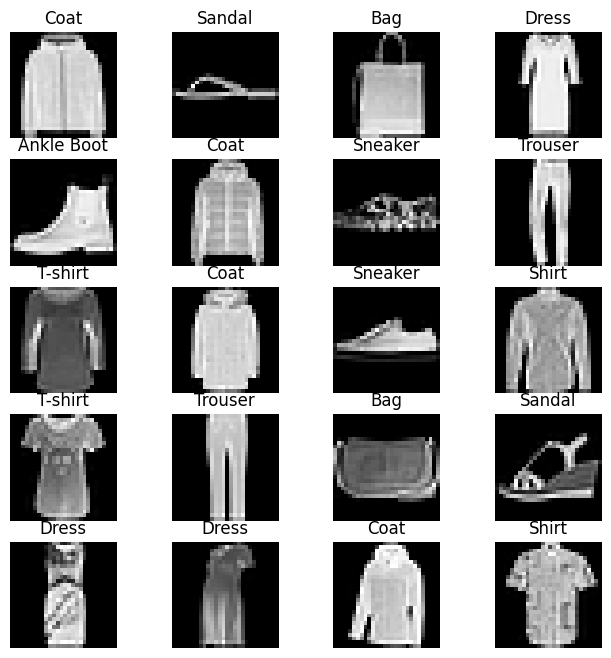

In [ ]:
## 분류에 사용될 클래스 정의

labels_map = {0: 'T-shirt', 1: 'Trouser', 2: 'Pullover', 3: 'Dress', 4: 'Coat', 5: 'Sandal', 6: 'Shirt', 7: 'Sneaker', 8: 'Bag', 9: 'Ankle Boot'}

fig = plt.figure(figsize=(8, 8))
columns = 4
rows = 5
for i in range(1, columns*rows + 1):
  img_xy = np.random.randint(len(train_dataset))
  img = train_dataset[img_xy][0][0,:,:]
  fig.add_subplot(rows, columns, i)
  plt.title(labels_map[train_dataset[img_xy][1]])
  plt.axis('off')
  plt.imshow(img, cmap='gray')
plt.show()



*   클래스 형태의 모델은 항상 torch.nn.Module을 상속받음. __init__()은 객체가 갖는 속성 값을 초기화하는 역할을 하며, 객체가 생성될 때 자동으로 호출됨.
*   객체란 메모리를 할당받아 프로그램에서 사용되는 모든 데이터를 의미하므로 변수, 함수 등은 모두 객체라고 할 수 있음. (* 객체명 = 클래스명())

*   nn은 딥러닝 모델 구성에 필요한 모듈이 모여 있는 패키지이며, Linear는 단순 선형 회귀 모델을 만들 때 사용함.
*   nn에서 사용되는 파라미터
1. in_features = 입력의 크기 (input size)
2. out_features = 출력의 크기 (output size)

*   torch.nn.Dropout(p)는 p만큼의 비율로 텐서의 값이 0이 되고, 0이 되지 않는 값들은 기존의 값에 (1/(1-p))만큼 곱해져 커짐. (e.g. p=0.3이라는 의미는 전체 값 중 0.3의 확률로 0이 된다)
*   forward() 함수는 모델이 학습 데이터를 입력받아 순전파 연산을 진행하는 함수이며, 객체를 데이터와 함께 호출하면 자동으로 실행됨 이 때 순전파 연산이란 H(x) 식에 입력 x로부터 예측된 y를 얻는 것임.

*   파이토치에서 사용하는 view는 넘파이의 reshape과 같은 역할로 텐서의 크기를 변경해주는 역할을 함. input_data.view(-1, 784)는 input_data를 (?, 784)의 크기로 변경하라는 의미이며, 이 때 첫번째 차원(-1)은 사용자가 잘 모르겠으니 파이토치에 맡기겠다는 의미임.
*   활성화 함수를 지정하는 방법
1. F.relu(): forward() 함수에서 정의
2. nn.relu(): __init__() 함수에서 정의









In [ ]:
## 심층 신경망 모델 생성

class FashionDNN(nn.Module):
  def __init__(self):
    super(FashionDNN, self).__init__()    ## nn.Module 클래스를 상속받겠다는 의미
    self.fc1 = nn.Linear(in_features=784, out_features=256)
    self.drop = nn.Dropout(0.25)
    self.fc2 = nn.Linear(in_features=256, out_features=128)
    self.fc3 = nn.Linear(in_features=128, out_features=10)

  def forward(self, input_data):
    out = input_data.view(-1, 784)
    out = F.relu(self.fc1(out))
    out = self.drop(out)
    out = F.relu(self.fc2(out))
    out = self.fc3(out)
    return out



*   옵티마이저를 위한 경사 하강법은 Adam을 사용함.



In [ ]:
## 심층 신경망에서 필요한 파라미터 정의

learning_rate = 0.001
model = FashionDNN()
model.to(device)

criterion = nn.CrossEntropyLoss()    ## 분류 문제에서 사용하는 손실 함수
optimizer = torch.optim.Adam(model.parameters(), lr=learning_rate)
print(model)

FashionDNN(
  (fc1): Linear(in_features=784, out_features=256, bias=True)
  (drop): Dropout(p=0.25, inplace=False)
  (fc2): Linear(in_features=256, out_features=128, bias=True)
  (fc3): Linear(in_features=128, out_features=10, bias=True)
)


In [ ]:
## 심층 신경망을 이용한 모델 학습

num_epochs = 5
count = 0
loss_list = []
iteration_list = []
accuracy_list = []

predictions_list = []
labels_list = []

for epoch in range(num_epochs):
  for images, labels in train_loader:
    images, labels = images.to(device), labels.to(device)

    train = Variable(images.view(100, 1, 28, 28))
    labels = Variable(labels)

    outputs = model(train)
    loss = criterion(outputs, labels)
    optimizer.zero_grad()
    loss.backward()
    optimizer.step()
    count += 1

    if not (count % 50):   ## count를 50으로 나누었을 때 나머지가 0이 아니라면 실행
      total = 0
      correct = 0
      for images, labels in test_loader:
        images, labels = images.to(device), labels.to(device)
        labels_list.append(labels)
        test = Variable(images.view(100, 1, 28, 28))
        outputs = model(test)
        predictions = torch.max(outputs, 1)[1].to(device)
        predictions_list.append(predictions)
        correct += (predictions == labels).sum()
        total += len(labels)

      accuracy = correct * 100 / total
      loss_list.append(loss.data)
      iteration_list.append(count)
      accuracy_list.append(accuracy)

    if not (count % 500):
      print("Iteration: {}, Loss: {}, Accuracy: {}%".format(count, loss.data, accuracy))

Iteration: 500, Loss: 0.5331394672393799, Accuracy: 83.47000122070312%
Iteration: 1000, Loss: 0.44125309586524963, Accuracy: 84.62999725341797%
Iteration: 1500, Loss: 0.3634740710258484, Accuracy: 84.30999755859375%
Iteration: 2000, Loss: 0.4280757009983063, Accuracy: 85.33000183105469%
Iteration: 2500, Loss: 0.23412756621837616, Accuracy: 86.13999938964844%
Iteration: 3000, Loss: 0.26025399565696716, Accuracy: 87.16000366210938%




*   nn.Sequential을 사용하면 __init__()에서 사용할 네트워크 모델들을 정의해줄 뿐만 아니라, forward() 함수에서 구현될 순전파를 계층 형태로 좀 더 가독성이 뛰어난 코드로 작성 가능함. 즉, nn.Sequential은 계층을 차례로 쌓을 수 있도록 Wx+b와 같은 수식과 활성화 함수를 연결해주는 역할을 함.
*   커널의 파라미터
1. in_channels: 입력 채널의 수를 의미함. 흑백 이미지는 1, RGB 값을 가진 이미지는 3을 가진 경우가 많음.
2. out_channels: 출력 채널의 수
3. kernel_size: 커널 크기를 의미하며 필터라고도 함. 커널은 이미지 특징을 찾아내기 위한 공용 파라미터이며, CNN에서 학습 대상은 필터 파라미터가 됨. 커널은 입력 데이터를 스트라이드 간격으로 순회하며 합성곱을 계산함.
4. padding: 패딩 크기를 의미하는 것으로 출력 크기를 조정하기 위해 입력 데이터 주위에 0을 채움. 패딩 값이 클수록 출력 크기도 커짐.

*   BatchNorm2d는 학습 과정에서 각 배치 단위별로 데이터가 다양한 분포를 가지더라도 평균과 분산을 이용해 정규화하는 것을 말함.
*   MaxPool2d는 이미지 크기를 축소시키는 용도로 사용됨.

*   MaxPool2d의 파라미터
1. kernel_size: m X n 행렬로 구성된 가중치
2. stride: 입력 데이터에 커널(필터)을 적용할 때 이동할 간격을 의미함. 스트라이드 값이 커지면 출력 크기는 작아짐.
*   클래스를 분류하기 위해서는 이미지 형태의 데이터를 배열 형태로 변환하여 작업해야 함. 이 때 Conv2d에서 사용하는 하이퍼파라미터 값들에 따라 출력 크기다 달라짐.









In [ ]:
## 합성곱 네트워크 생성

class FashionCNN(nn.Module):
  def __init__(self):
    super(FashionCNN, self).__init__()
    self.layer1 = nn.Sequential(nn.Conv2d(in_channels=1, out_channels=32, kernel_size=3, padding=1), nn.BatchNorm2d(32), nn.ReLU(), nn.MaxPool2d(kernel_size=2, stride=2))
    self.layer2 = nn.Sequential(nn.Conv2d(in_channels=32, out_channels=64, kernel_size=3), nn.BatchNorm2d(64), nn.ReLU(), nn.MaxPool2d(2))
    self.fc1 = nn.Linear(in_features=64*6*6, out_features=600)
    self.drop = nn.Dropout2d(0.25)
    self.fc2 = nn.Linear(in_features=600, out_features=120)
    self.fc3 = nn.Linear(in_features=120, out_features=10)

  def forward(self, x):
    out = self.layer1(x)
    out = self.layer2(out)
    out = out.view(out.size(0), -1)
    out = self.fc1(out)
    out = self.drop(out)
    out = self.fc2(out)
    out = self.fc3(out)
    return out

In [ ]:
## 합성곱 네트워크를 위한 파라미터 정의

learning_rate = 0.001
model = FashionCNN()
model.to(device)

criterion = nn.CrossEntropyLoss()
optimizer = torch.optim.Adam(model.parameters(), lr=learning_rate)
print(model)

FashionCNN(
  (layer1): Sequential(
    (0): Conv2d(1, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (1): BatchNorm2d(32, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (2): ReLU()
    (3): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  )
  (layer2): Sequential(
    (0): Conv2d(32, 64, kernel_size=(3, 3), stride=(1, 1))
    (1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (2): ReLU()
    (3): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  )
  (fc1): Linear(in_features=2304, out_features=600, bias=True)
  (drop): Dropout2d(p=0.25, inplace=False)
  (fc2): Linear(in_features=600, out_features=120, bias=True)
  (fc3): Linear(in_features=120, out_features=10, bias=True)
)


In [ ]:
## 모델 학습 및 성능 평가

num_epochs = 5
count = 0
loss_list = []
iteration_list = []
accuracy_list = []

predictions_list = []
labels_list = []

for epoch in range(num_epochs):
  for images, labels in train_loader:
    images, labels = images.to(device), labels.to(device)

    train = Variable(images.view(100, 1, 28, 28))
    labels = Variable(labels)

    outputs = model(train)
    loss = criterion(outputs, labels)
    optimizer.zero_grad()
    loss.backward()
    optimizer.step()
    count += 1

    if not (count % 50):   ## count를 50으로 나누었을 때 나머지가 0이 아니라면 실행
      total = 0
      correct = 0
      for images, labels in test_loader:
        images, labels = images.to(device), labels.to(device)
        labels_list.append(labels)
        test = Variable(images.view(100, 1, 28, 28))
        outputs = model(test)
        predictions = torch.max(outputs, 1)[1].to(device)
        predictions_list.append(predictions)
        correct += (predictions == labels).sum()
        total += len(labels)

      accuracy = correct * 100 / total
      loss_list.append(loss.data)
      iteration_list.append(count)
      accuracy_list.append(accuracy)

    if not (count % 500):
      print("Iteration: {}, Loss: {}, Accuracy: {}%".format(count, loss.data, accuracy))

/usr/local/lib/python3.13/dist-packages/torch/nn/modules/dropout.py:176: UserWarning: dropout2d: Received a 2-D input to dropout2d, which is deprecated and will result in an error in a future release. To retain the behavior and silence this warning, please use dropout instead. Note that dropout2d exists to provide channel-wise dropout on inputs with 2 spatial dimensions, a channel dimension, and an optional batch dimension (i.e. 3D or 4D inputs).
  return F.dropout2d(input, self.p, self.training, self.inplace)


Iteration: 500, Loss: 0.5316089391708374, Accuracy: 87.37999725341797%
Iteration: 1000, Loss: 0.31207406520843506, Accuracy: 87.75%
Iteration: 1500, Loss: 0.26203423738479614, Accuracy: 88.4800033569336%
Iteration: 2000, Loss: 0.18352997303009033, Accuracy: 89.25%
Iteration: 2500, Loss: 0.11123642325401306, Accuracy: 89.80999755859375%
Iteration: 3000, Loss: 0.16755792498588562, Accuracy: 90.33999633789062%
